## 用于计算数据增强方法对比实验中的三个评价指标

In [4]:
import sys
import numpy as np
import pandas as pd
from pathlib import Path


# ============================================================
# 路径与表名（results.xlsx 与本 notebook 同目录）
# ============================================================

# results.xlsx 与本 notebook 同目录（相对路径，依赖当前工作目录）
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'run.py').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
RESULT_XLSX = PROJECT_ROOT / 'results/results.xlsx'

# 各工作表：原始数据行范围 + 汇总结果写入行范围（Excel 1-based 行号）
SHEET_CONFIG = {
    # "CAEEG": {
    #     "data_row_start": 44,
    #     "data_row_end": 107,
    #     "result_row_start": 110,
    #     "result_row_end": 120,
    # },
    "CAUEEG": {
        "data_row_start": 24,
        "data_row_end": 87,
        "result_row_start": 90,
        "result_row_end": 100,
    },
}

# 若名字以这些后缀结尾，则最后一段视为增强模式，否则视为「无后缀」旧格式
KNOWN_AUGMENTATION_SUFFIXES = (
    "noAugmentation",
    "Channel",
    "Drop",
    "Flip",
    "Frequency",
    "Jitter",
    "Mask",
    "FreMixing",
    "oneFreBanDAGnoRanCrop",
    "oneFreBanDTABGnoRanCrop",
    "threeFreBanDAGnoRanCrop",
    "oneFreBanTBnoRanCrop"
)

# 汇总区第一列标签格式：{base}_vs_{compare}，例如 noAugmentation_vs_Channel
RESULTS_BASE_AUG = "noAugmentation"

# 可选：只统计指定 dataset / task（与模型名解析出的字段精确匹配）
# None = 不限制；str = 只保留该值；tuple/set/list[str] = 白名单（命中其一即保留）
RESULTS_FILTER_DATASET = None
RESULTS_FILTER_TASK = None

# 仅使用五折交叉验证列（排除 “各 ITR 平均±标准差” 等汇总列）
ITR_LABELS = [f"ITR {i}" for i in range(1, 6)]

# ============================================================
# 指标权重（与下方列名映射一致）
# ============================================================

METRIC_WEIGHTS = {
    "F1": 0.30,
    "k-score": 0.25,
    "AUPRC": 0.20,
    "AUROC": 0.15,
    "Accuracy": 0.10,
}
METRIC_RANGES = {
    "F1": 1.0,
    "k-score": 2.0,   # 如果你的 k-score 用百分数表示：-100 ~ 100
    "AUROC": 1.0,
    "AUPRC": 1.0,
    "Accuracy": 1.0,
}

# Sample-level / Subject-level：Excel 第二行子列名 -> 与 METRIC_WEIGHTS 相同的键
SAMPLE_METRIC_COLS = {
    "Accuracy": "Accuracy1",
    "F1": "F11",
    "k-score": "k-score1",
    "AUROC": "AUROC1",
    "AUPRC": "AUPRC1",
}
SUBJECT_METRIC_COLS = {
    "Accuracy": "Accuracy2",
    "F1": "F12",
    "k-score": "k-score2",
    "AUROC": "AUROC2",
    "AUPRC": "AUPRC2",
}


In [5]:
# ============================================================
# 工具函数
# ============================================================

def safe_std(x):
    """
    防止 std=0 导致除零
    """
    s = np.std(x, ddof=1)
    if s < 1e-8:
        s = 1e-8
    return s


# ============================================================
# 1. ABS (Augmentation Benefit Score)
# ============================================================

def compute_abs(results_base, results_aug, metric_weights):
    """
    ABS:
    加权平均相对提升

    Parameters
    ----------
    results_base : dict
        baseline结果

    results_aug : dict
        augmentation结果

    metric_weights : dict
        指标权重

    Returns
    -------
    abs_score : float
    details : dict
    """

    abs_score = 0.0
    details = {}

    for metric, weight in metric_weights.items():

        base = np.array(results_base[metric])
        aug = np.array(results_aug[metric])

        # 相对提升
        rel_improve = (aug - base) / (base + 1e-8)

        mean_rel_improve = np.mean(rel_improve)

        abs_score += weight * mean_rel_improve

        details[metric] = {
            "mean_relative_improvement": mean_rel_improve,
            "weighted_contribution": weight * mean_rel_improve
        }

    return abs_score, details

def compute_abs_normalized(results_base, results_aug,
                           metric_weights=METRIC_WEIGHTS,
                           metric_ranges=METRIC_RANGES):
    """
    Normalized ABS:
    适用于 Kappa/k-score 可能为负值的情况。

    ABS = sum_j w_j * mean(aug_j - base_j) / range_j

    注意：
    如果你的 k-score 是 Cohen's kappa 原始值，例如 -1 ~ 1，
    则 METRIC_RANGES["k-score"] 应该改为 2.0。
    如果你的 k-score 是百分数，例如 -100 ~ 100，
    则使用 200.0。
    """

    abs_score = 0.0
    details = {}

    for metric, weight in metric_weights.items():
        base = np.asarray(results_base[metric], dtype=float)
        aug = np.asarray(results_aug[metric], dtype=float)

        if base.shape != aug.shape:
            raise ValueError(f"{metric}: base 和 aug 的形状不一致")

        delta = aug - base
        mean_delta = np.mean(delta)

        metric_range = metric_ranges[metric]
        normalized_gain = mean_delta / metric_range

        weighted_contribution = weight * normalized_gain
        abs_score += weighted_contribution

        details[metric] = {
            "mean_base": float(np.mean(base)),
            "mean_aug": float(np.mean(aug)),
            "mean_delta": float(mean_delta),
            "metric_range": metric_range,
            "normalized_gain": float(normalized_gain),
            "weighted_contribution": float(weighted_contribution),
        }

    return abs_score, details


# ============================================================
# 2. ACS (Augmentation Consistency Score)
# ============================================================

def compute_acs(results_base, results_aug, metric_weights):
    """
    ACS:
    加权稳定增益评分

    ACS = mean(delta) / std(delta)

    Returns
    -------
    acs_score : float
    details : dict
    """

    acs_score = 0.0
    details = {}

    for metric, weight in metric_weights.items():

        base = np.array(results_base[metric])
        aug = np.array(results_aug[metric])

        delta = aug - base

        mean_delta = np.mean(delta)
        std_delta = safe_std(delta)

        acs_metric = mean_delta / std_delta

        acs_score += weight * acs_metric

        details[metric] = {
            "mean_delta": mean_delta,
            "std_delta": std_delta,
            "acs_metric": acs_metric,
            "weighted_contribution": weight * acs_metric
        }

    return acs_score, details


# ============================================================
# 3. Win Rate
# ============================================================

def compute_win_rate(results_base, results_aug, metric_weights=None):
    """
    Win Rate:
    提升比例

    Returns
    -------
    win_rate : float
    details : dict
    """

    total = 0
    wins = 0

    details = {}

    for metric in results_base.keys():

        base = np.array(results_base[metric])
        aug = np.array(results_aug[metric])

        delta = aug - base

        metric_wins = np.sum(delta > 0)

        metric_total = len(delta)

        metric_win_rate = metric_wins / metric_total

        wins += metric_wins
        total += metric_total

        details[metric] = {
            "wins": int(metric_wins),
            "total": int(metric_total),
            "win_rate": metric_win_rate
        }

    overall_win_rate = wins / total

    return overall_win_rate, details


# ============================================================
# 4. 综合评价
# ============================================================

def evaluate_augmentation(results_base, results_aug,
                          metric_weights=METRIC_WEIGHTS):

    # abs_score, abs_details = compute_abs(
    #     results_base,
    #     results_aug,
    #     metric_weights
    # )

    abs_score, abs_details = compute_abs_normalized(
        results_base,
        results_aug,
        metric_weights
    )

    acs_score, acs_details = compute_acs(
        results_base,
        results_aug,
        metric_weights
    )

    win_rate, win_details = compute_win_rate(
        results_base,
        results_aug
    )

    return {
        "ABS": abs_score,
        "ACS": acs_score,
        "WinRate": win_rate,

        "ABS_details": abs_details,
        "ACS_details": acs_details,
        "WinRate_details": win_details
    }


# ============================================================
# 5. 结果表：解析模型名、按折提取指标、配对两种增强模式
# ============================================================


def parse_model_name(model_name):
    """
    解析第一列模型名。
    形如: Dataset-Model-Task-noAugmentation
    若末尾不在 KNOWN_AUGMENTATION_SUFFIXES，则按无后缀旧格式 Dataset-Model-Task 解析（aug=None）。
    """
    if model_name is None:
        return None
    if isinstance(model_name, float) and np.isnan(model_name):
        return None
    s = str(model_name).strip()
    if not s:
        return None
    parts = s.split("-")
    if len(parts) < 3:
        return None
    if parts[-1] in KNOWN_AUGMENTATION_SUFFIXES:
        aug = parts[-1]
        task = parts[-2]
        model = parts[-3]
        dataset = "-".join(parts[:-3])
    else:
        aug = None
        task = parts[-1]
        model = parts[-2]
        dataset = "-".join(parts[:-2])
    return {
        "raw": s,
        "dataset": dataset,
        "model": model,
        "task": task,
        "aug": aug,
    }


def _get_row_series(df: pd.DataFrame, label):
    """index 重复时取首行。"""
    obj = df.loc[label]
    if isinstance(obj, pd.DataFrame):
        return obj.iloc[0]
    return obj


def row_to_results_by_fold(row: pd.Series, metric_col_map: dict) -> dict:
    """
    将一行转为 evaluate_augmentation 所需的 dict:
    每个键对应长度为 len(ITR_LABELS) 的列表（五折顺序）。
    """
    out = {}
    for met_key, xl_sub in metric_col_map.items():
        vals = []
        for itr in ITR_LABELS:
            col = (itr, xl_sub)
            if col not in row.index:
                vals.append(np.nan)
            else:
                vals.append(row[col])
        out[met_key] = vals
    return out


def load_results_table(
    path=None,
    sheet_name=None,
    data_row_start: int | None = None,
    data_row_end: int | None = None,
) -> pd.DataFrame:
    """读取结果表；可选按 Excel 行号截取原始数据区。"""
    path = Path(path) if path is not None else RESULT_XLSX
    df = pd.read_excel(path, sheet_name=sheet_name, header=[0, 1], index_col=0)
    df = df.loc[df.index.notna()]
    df.index = df.index.astype(str).str.strip()
    df = df.loc[df.index != ""]
    if data_row_start is not None and data_row_end is not None:
        full = pd.read_excel(path, sheet_name=sheet_name, header=None)
        names = (
            full.iloc[data_row_start - 1 : data_row_end, 0]
            .dropna()
            .astype(str)
            .str.strip()
        )
        names = names[names != ""]
        df = df.loc[df.index.intersection(names)]
    return df


def parse_comparison_label(label: str) -> tuple[str, str]:
    """解析汇总区标签，如 noAugmentation_vs_Channel -> (noAugmentation, Channel)。"""
    parts = str(label).strip().split("_vs_")
    if len(parts) != 2 or not all(parts):
        raise ValueError(f"无法解析对比标签: {label!r}")
    return parts[0], parts[1]


def _matches_optional_filter(value, filt):
    """filt 为 None 时不过滤；为 str 时精确匹配；为 tuple/set/list 等可迭代时 value 须在该集合中。"""
    if filt is None:
        return True
    if isinstance(filt, str):
        return value == filt
    return value in filt


def build_aug_pairs(
    df: pd.DataFrame,
    base_aug: str,
    compare_aug: str,
    filter_dataset=RESULTS_FILTER_DATASET,
    filter_task=RESULTS_FILTER_TASK,
) -> list:
    """
    对同一 (dataset, model, task)，同时存在 base_aug 与 compare_aug 时配对。
    返回 dict 列表，含 row_base / row_aug 的索引标签（模型名字符串）。
    """
    groups = {}
    for raw_name, row in df.iterrows():
        info = parse_model_name(raw_name)
        if info is None or info["aug"] is None:
            continue
        if info["aug"] not in (base_aug, compare_aug):
            continue
        if not _matches_optional_filter(info["dataset"], filter_dataset):
            continue
        if not _matches_optional_filter(info["task"], filter_task):
            continue
        key = (info["dataset"], info["model"], info["task"])
        groups.setdefault(key, {})[info["aug"]] = raw_name
    pairs = []
    for key, mp in groups.items():
        if base_aug in mp and compare_aug in mp:
            pairs.append(
                {
                    "dataset": key[0],
                    "model": key[1],
                    "task": key[2],
                    "row_base": mp[base_aug],
                    "row_aug": mp[compare_aug],
                }
            )
    return pairs


def compute_paired_scores(
    df: pd.DataFrame,
    metric_col_map: dict,
    level_name: str,
    base_aug: str,
    compare_aug: str,
) -> pd.DataFrame:
    """compare_aug 相对 base_aug 的综合评分（Sample 或 Subject）。"""
    records = []
    for p in build_aug_pairs(df, base_aug, compare_aug):
        base = row_to_results_by_fold(_get_row_series(df, p["row_base"]), metric_col_map)
        aug = row_to_results_by_fold(_get_row_series(df, p["row_aug"]), metric_col_map)
        ev = evaluate_augmentation(base, aug, METRIC_WEIGHTS)
        records.append(
            {
                "dataset": p["dataset"],
                "model": p["model"],
                "task": p["task"],
                "level": level_name,
                "model_base": p["row_base"],
                "model_aug": p["row_aug"],
                "ABS": ev["ABS"],
                "ACS": ev["ACS"],
                "WinRate": ev["WinRate"],
                "ABS_details": ev["ABS_details"],
                "ACS_details": ev["ACS_details"],
                "WinRate_details": ev["WinRate_details"],
            }
        )
    return pd.DataFrame(records)


def compute_mean_scores_for_comparison(
    df: pd.DataFrame,
    base_aug: str,
    compare_aug: str,
) -> dict | None:
    """计算某一组增强对比下，所有模型在 Sample / Subject 两个层级的 ABS/ACS/WinRate 均值。"""
    scores_sample = compute_paired_scores(
        df, SAMPLE_METRIC_COLS, "Sample-level", base_aug, compare_aug
    )
    scores_subject = compute_paired_scores(
        df, SUBJECT_METRIC_COLS, "Subject-level", base_aug, compare_aug
    )
    if scores_sample.empty or scores_subject.empty:
        return None
    return {
        "sample": {
            "ABS": float(scores_sample["ABS"].mean()),
            "ACS": float(scores_sample["ACS"].mean()),
            "WinRate": float(scores_sample["WinRate"].mean()),
        },
        "subject": {
            "ABS": float(scores_subject["ABS"].mean()),
            "ACS": float(scores_subject["ACS"].mean()),
            "WinRate": float(scores_subject["WinRate"].mean()),
        },
        "n_models": len(scores_sample),
    }


def write_sheet_summary_results(
    path,
    sheet_name: str,
    result_row_start: int,
    result_row_end: int,
    results_by_label: dict,
) -> None:
    """
    将均值写入汇总区：
    B-D 列 = Sample-level (ABS 1 / ACS 1 / WinRate 1)
    F-H 列 = Subject-level (ABS 2 / ACS 2 / WinRate 2)
    """
    from openpyxl import load_workbook

    path = Path(path)
    wb = load_workbook(path)
    ws = wb[sheet_name]
    full = pd.read_excel(path, sheet_name=sheet_name, header=None)

    for excel_row in range(result_row_start, result_row_end + 1):
        label = full.iloc[excel_row - 1, 0]
        if pd.isna(label) or str(label).strip() == "":
            continue
        label = str(label).strip()
        if label not in results_by_label:
            print(f"  警告 [{sheet_name}] 行 {excel_row}: 未计算 {label}")
            continue
        r = results_by_label[label]
        ws.cell(row=excel_row, column=2, value=r["sample"]["ABS"])
        ws.cell(row=excel_row, column=3, value=r["sample"]["ACS"])
        ws.cell(row=excel_row, column=4, value=r["sample"]["WinRate"])
        ws.cell(row=excel_row, column=6, value=r["subject"]["ABS"])
        ws.cell(row=excel_row, column=7, value=r["subject"]["ACS"])
        ws.cell(row=excel_row, column=8, value=r["subject"]["WinRate"])

    wb.save(path)

In [6]:
from IPython.display import display

# 遍历 CAEEG / CAUEEG 两个工作表，按汇总区标签批量计算并写回 results.xlsx

summary_records = []

for sheet_name, cfg in SHEET_CONFIG.items():
    print(f"\n===== {sheet_name} =====")
    df = load_results_table(
        RESULT_XLSX,
        sheet_name,
        data_row_start=cfg["data_row_start"],
        data_row_end=cfg["data_row_end"],
    )
    print(f"读取数据行 {cfg['data_row_start']}-{cfg['data_row_end']}，共 {len(df)} 条模型记录")

    full = pd.read_excel(RESULT_XLSX, sheet_name=sheet_name, header=None)
    results_by_label = {}

    for excel_row in range(cfg["result_row_start"], cfg["result_row_end"] + 1):
        label = full.iloc[excel_row - 1, 0]
        if pd.isna(label) or str(label).strip() == "":
            continue
        label = str(label).strip()
        base_aug, compare_aug = parse_comparison_label(label)

        mean_scores = compute_mean_scores_for_comparison(df, base_aug, compare_aug)
        if mean_scores is None:
            print(f"  行 {excel_row} {label}: 未找到配对模型，跳过")
            continue

        results_by_label[label] = mean_scores
        print(
            f"  行 {excel_row} {label} (n={mean_scores['n_models']}): "
            f"Sample ABS={mean_scores['sample']['ABS']:.6f}, "
            f"Subject ABS={mean_scores['subject']['ABS']:.6f}"
        )
        summary_records.append(
            {
                "sheet": sheet_name,
                "comparison": label,
                "base_aug": base_aug,
                "compare_aug": compare_aug,
                "n_models": mean_scores["n_models"],
                "ABS_sample": mean_scores["sample"]["ABS"],
                "ACS_sample": mean_scores["sample"]["ACS"],
                "WinRate_sample": mean_scores["sample"]["WinRate"],
                "ABS_subject": mean_scores["subject"]["ABS"],
                "ACS_subject": mean_scores["subject"]["ACS"],
                "WinRate_subject": mean_scores["subject"]["WinRate"],
            }
        )

    write_sheet_summary_results(
        RESULT_XLSX,
        sheet_name,
        cfg["result_row_start"],
        cfg["result_row_end"],
        results_by_label,
    )
    print(f"已写回 {RESULT_XLSX.name} -> 工作表 {sheet_name} 行 {cfg['result_row_start']}-{cfg['result_row_end']}")

summary_df = pd.DataFrame(summary_records)
display(summary_df)
print(f"\n全部完成，结果已保存至: {RESULT_XLSX}")


===== CAUEEG =====
读取数据行 24-87，共 65 条模型记录
  行 90 noAugmentation_vs_Channel (n=5): Sample ABS=-0.002445, Subject ABS=0.000995
  行 91 noAugmentation_vs_Drop (n=5): Sample ABS=-0.005202, Subject ABS=-0.001271
  行 92 noAugmentation_vs_Flip (n=5): Sample ABS=-0.002127, Subject ABS=-0.008908
  行 93 noAugmentation_vs_Frequency (n=5): Sample ABS=-0.004902, Subject ABS=-0.003672
  行 94 noAugmentation_vs_Jitter (n=5): Sample ABS=-0.005381, Subject ABS=-0.001363
  行 95 noAugmentation_vs_Mask (n=5): Sample ABS=-0.002265, Subject ABS=0.005796
  行 96 noAugmentation_vs_FreMixing (n=5): Sample ABS=-0.011660, Subject ABS=-0.013428
  行 97 noAugmentation_vs_oneFreBanTBnoRanCrop (n=5): Sample ABS=-0.002519, Subject ABS=0.001485
  行 98 noAugmentation_vs_threeFreBanDAGnoRanCrop (n=5): Sample ABS=-0.003095, Subject ABS=0.001478
  行 99 noAugmentation_vs_oneFreBanDTABGnoRanCrop (n=5): Sample ABS=-0.005078, Subject ABS=-0.004793
  行 100 noAugmentation_vs_oneFreBanDAGnoRanCrop (n=5): Sample ABS=0.001071, Subjec

,sheet,comparison,base_aug,compare_aug,n_models,ABS_sample,ACS_sample,WinRate_sample,ABS_subject,ACS_subject,WinRate_subject
0,CAUEEG,noAugmentation_vs_Channel,noAugmentation,Channel,5,-0.002445,-0.061002,0.504,0.000995,0.016946,0.528
1,CAUEEG,noAugmentation_vs_Drop,noAugmentation,Drop,5,-0.005202,-0.123424,0.448,-0.001271,-0.045519,0.464
2,CAUEEG,noAugmentation_vs_Flip,noAugmentation,Flip,5,-0.002127,-0.022722,0.536,-0.008908,-0.187077,0.504
3,CAUEEG,noAugmentation_vs_Frequency,noAugmentation,Frequency,5,-0.004902,-0.136470,0.448,-0.003672,-0.080514,0.520
4,CAUEEG,noAugmentation_vs_Jitter,noAugmentation,Jitter,5,-0.005381,-0.180916,0.464,-0.001363,-0.034150,0.536
5,CAUEEG,noAugmentation_vs_Mask,noAugmentation,Mask,5,-0.002265,-0.053118,0.536,0.005796,0.101405,0.616
6,CAUEEG,noAugmentation_vs_FreMixing,noAugmentation,FreMixing,5,-0.011660,-0.394007,0.368,-0.013428,-0.303718,0.432
7,CAUEEG,noAugmentation_vs_oneFreBanTBnoRanCrop,noAugmentation,oneFreBanTBnoRanCrop,5,-0.002519,-0.059299,0.488,0.001485,0.023515,0.560
8,CAUEEG,noAugmentation_vs_threeFreBanDAGnoRanCrop,noAugmentation,threeFreBanDAGnoRanCrop,5,-0.003095,-0.051711,0.480,0.001478,0.034096,0.584
9,CAUEEG,noAugmentation_vs_oneFreBanDTABGnoRanCrop,noAugmentation,oneFreBanDTABGnoRanCrop,5,-0.005078,-0.146687,0.472,-0.004793,-0.102468,0.504



全部完成，结果已保存至: /root/autodl-tmp/ADSST-Net/results/results.xlsx


## 数据增强流程图 素材 绘制

-**注：** 本代码在本地运行

### FFT 频谱包络（训练集内两样本）

1. 按 `Prior-Guided_Graph_Learning_Explainability` 相同参数加载 TRAIN（`CAEEG3_1.0s_0.0_EO_Aug`，第 1 折 `seed=39`）
2. 由 `FFT_SAMPLE_SEED` 随机选样本 A，再选同类、不同受试者的样本 B（改种子即可换样本）
3. 对原始视图 `(T, C)` 做 rFFT，绘制各通道 min–max 包络
4. 保存 2 张 PNG 至 `figs/DataAug_Flowchart/`

In [1]:
# --- FFT 频谱包络：依赖与路径（本段独立，不调用上文工具函数）---
import sys
import random
from argparse import Namespace
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np

_fft_nb_root = Path.cwd().resolve()
if not (_fft_nb_root / 'run.py').exists():
    _fft_nb_root = _fft_nb_root.parent
if str(_fft_nb_root) not in sys.path:
    sys.path.insert(0, str(_fft_nb_root))

from data_provider.data_factory import data_dict

FFT_PROJECT_ROOT = _fft_nb_root
FFT_BASE_SEED = 38
FFT_FOLD_SEED = FFT_BASE_SEED + 1
FFT_SFREQ = 128
FFT_COLOR_SAMPLE_A = 'steelblue'
FFT_COLOR_SAMPLE_B = 'darkorange'
FFT_CLASS_NAMES = {0: 'NC', 1: 'MCI', 2: 'AD'}

# 绘图样式（可在单元 6 调用时覆盖，或只改此处）
FFT_FREQUENCY_BANDS = {
    'Delta-Theta': 4,
    'Theta-Alpha': 8,
    'Alpha-Beta': 13,
    'Beta-Gamma': 30,
}
FFT_BAND_VLINE_WIDTH = 5       # 频带分界虚线线宽
FFT_BAND_VLINE_COLOR = 'red'   # 频带分界虚线颜色
FFT_BAND_LABEL_FONTSIZE = 60   # 频带分界文字字号
FFT_BAND_LABEL_COLOR = 'black' # 频带分界文字颜色
FFT_ENVELOPE_LINEWIDTH = 5     # 包络边线线宽

FFT_ARGS = Namespace(
    seed=FFT_BASE_SEED,
    data='CAEEG',
    root_path=str((FFT_PROJECT_ROOT / 'dataset/CAEEG3_1.0s_0.0_EO_Aug').resolve()) + '/',
    selected_classes=[0, 1, 2],
    cross_val='mccv',
    topk_A0=4,
)

# 修改此种子可换一组样本 A/B（与训练集划分种子 FFT_FOLD_SEED 独立）
FFT_SAMPLE_SEED = 58
FFT_SHOW_PREVIEW = True

FFT_OUTPUT_DIR = FFT_PROJECT_ROOT / 'figs' / 'fonts'
FFT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
font_manager.fontManager.addfont(FFT_PROJECT_ROOT / 'figs/fonts/TIMES.TTF')

plt.rcParams.update({
    'font.family': 'Times New Roman',
    'font.serif': ['Times New Roman'],
    'axes.unicode_minus': False,
})

print(f'FFT_PROJECT_ROOT = {FFT_PROJECT_ROOT}')
print(f'FFT root_path      = {FFT_ARGS.root_path}')
print(f'FFT_OUTPUT_DIR     = {FFT_OUTPUT_DIR}')
print(f'FFT_FOLD_SEED      = {FFT_FOLD_SEED}  (TRAIN 划分)')
print(f'FFT_SAMPLE_SEED    = {FFT_SAMPLE_SEED}  (样本 A/B 配对，改此值换样本)')

FFT_PROJECT_ROOT = /root/autodl-tmp/ADSST-Net
FFT root_path      = /root/autodl-tmp/ADSST-Net/dataset/CAEEG3_1.0s_0.0_EO_Aug/
FFT_OUTPUT_DIR     = /root/autodl-tmp/ADSST-Net/figs/fonts
FFT_FOLD_SEED      = 39  (TRAIN 划分)
FFT_SAMPLE_SEED    = 58  (样本 A/B 配对，改此值换样本)


In [2]:
def fft_load_train_dataset(seed: int):
    """按指定 seed 加载 TRAIN 集（与 run.py / exp_supervised 一致）。"""
    fold_args = Namespace(**vars(FFT_ARGS))
    fold_args.seed = seed
    random.seed(seed)
    np.random.seed(seed)
    return data_dict[fold_args.data](args=fold_args, flag='TRAIN', log=None)


def fft_pick_same_class_diff_subject(y: np.ndarray, rng: np.random.Generator):
    """随机选一个样本，再选同类、不同受试者的另一样本。返回 (idx_a, idx_b)。"""
    labels = y[:, 0].astype(int)
    subjects = y[:, 1].astype(int)
    idx_a = int(rng.integers(0, len(y)))
    lab = labels[idx_a]
    sub_a = subjects[idx_a]
    candidates = np.where((labels == lab) & (subjects != sub_a))[0]
    if candidates.size == 0:
        raise RuntimeError(
            f'类别 {lab} 中除受试者 {sub_a} 外无其它样本，无法配对。'
        )
    idx_b = int(rng.choice(candidates))
    return idx_a, idx_b


def fft_compute_channel_envelope(x_tc: np.ndarray, sfreq: int = FFT_SFREQ):
    """对 (T, C) 时序做 rFFT，返回频率轴及跨通道 min/max 包络。"""
    spectrum = np.abs(np.fft.rfft(x_tc, axis=0))
    freqs = np.fft.rfftfreq(x_tc.shape[0], d=1.0 / sfreq)
    return freqs, spectrum.min(axis=1), spectrum.max(axis=1)


def fft_plot_sample_envelope(
    freqs,
    min_amp,
    max_amp,
    *,
    title: str,
    save_path: Path | None = None,
    envelope_color: str = 'steelblue',
    alpha: float = 0.7,
    subplot_title_fontsize: int = 14,
    frequency_bands: dict | None = None,
    band_vline_linewidth: float | None = None,
    band_vline_color: str | None = None,
    band_label_fontsize: int | None = None,
    band_label_color: str | None = None,
    envelope_linewidth: float | None = None,
    show_preview: bool = False,
):
    """单样本 FFT 包络 + 频带分界竖线（无坐标轴、无网格）。"""
    bands = frequency_bands if frequency_bands is not None else FFT_FREQUENCY_BANDS
    vline_lw = band_vline_linewidth if band_vline_linewidth is not None else FFT_BAND_VLINE_WIDTH
    vline_color = band_vline_color if band_vline_color is not None else FFT_BAND_VLINE_COLOR
    label_fs = band_label_fontsize if band_label_fontsize is not None else FFT_BAND_LABEL_FONTSIZE
    label_color = band_label_color if band_label_color is not None else FFT_BAND_LABEL_COLOR
    env_lw = envelope_linewidth if envelope_linewidth is not None else FFT_ENVELOPE_LINEWIDTH

    fig, ax = plt.subplots(1, 1, figsize=(14, 8))
    ax.fill_between(
        freqs, min_amp, max_amp,
        color=envelope_color, alpha=alpha,
        edgecolor=envelope_color, linewidth=env_lw,
    )

    x_max = min(FFT_SFREQ / 2, 50)
    ax.set_xlim(0, x_max)

    _, y_max = ax.get_ylim()
    for _, freq_boundary in bands.items():
        if freq_boundary <= freqs[-1]:
            ax.axvline(
                x=freq_boundary, color=vline_color, linestyle='--',
                linewidth=vline_lw, alpha=0.6, zorder=1,
            )
            ax.text(
                freq_boundary, y_max * 0.95, f'{freq_boundary} Hz',
                rotation=90, verticalalignment='top', horizontalalignment='right',
                fontsize=label_fs, fontfamily='Times New Roman', color=label_color, alpha=0.8,
            )

    ax.axis('off')
    ax.set_title(title, fontsize=subplot_title_fontsize, fontweight='bold', fontfamily='Times New Roman', pad=20)
    plt.tight_layout()

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=600, bbox_inches='tight')
        print(f'Figure saved to: {save_path}')

    if show_preview:
        try:
            from IPython.display import display
            display(fig)
        except ImportError:
            plt.show()
        print(f'[Preview] {title}')

    return fig, ax

train ids: [2, 5, 6, 7, 8, 11, 13, 14, 15, 17, 19, 20, 22, 27, 29, 31, 32, 33, 34, 35, 36, 38, 39, 41, 42, 44, 46, 48, 49, 50, 52, 54, 55, 56, 57, 59, 60, 61, 64, 67, 69, 70, 74, 75, 77, 78, 79, 80, 81, 82, 84, 88, 90, 91, 92, 93, 96, 97, 98, 99, 100, 101, 102, 104, 105, 106, 107, 108, 109, 111] (数量: 70)
样本配对随机种子: FFT_SAMPLE_SEED = 58
TRAIN 样本数: 12424
样本 A: index=6337, class=MCI(1), subject=31
样本 B: index=3844, class=MCI(1), subject=22
Figure saved to: /root/autodl-tmp/ADSST-Net/figs/fonts/FFT_envelope_MCI_subj031_idx6337.svg


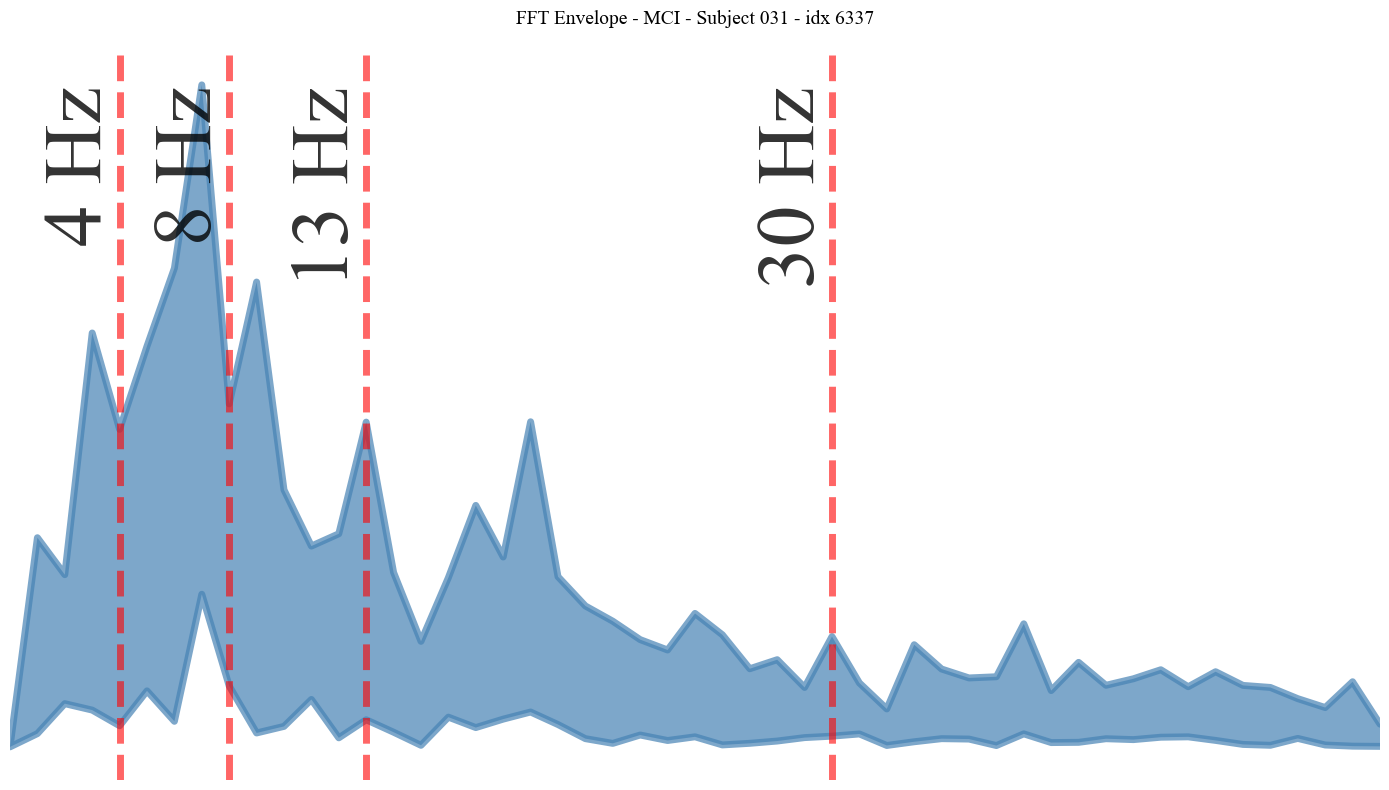

[Preview] FFT Envelope - MCI - Subject 031 - idx 6337
Figure saved to: /root/autodl-tmp/ADSST-Net/figs/fonts/FFT_envelope_MCI_subj022_idx3844.svg


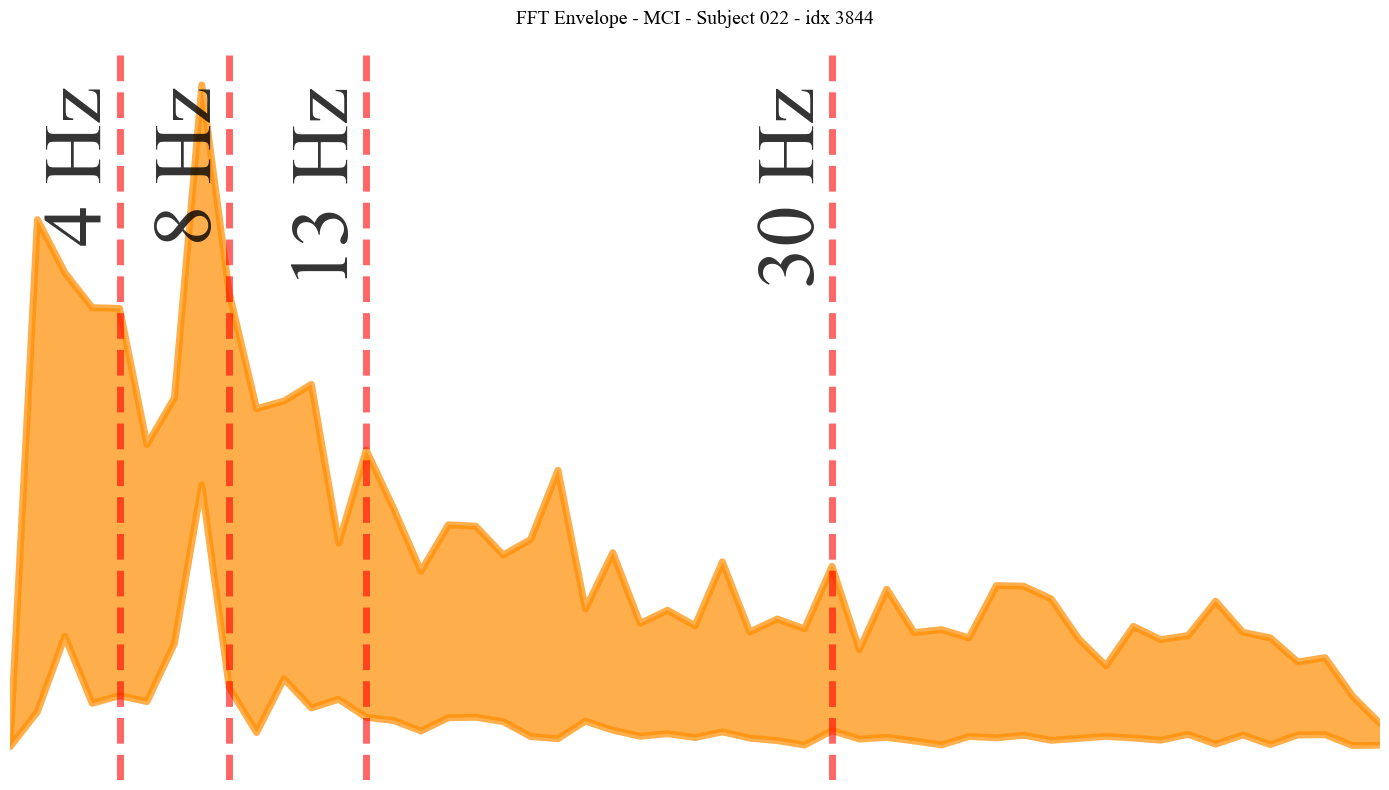

[Preview] FFT Envelope - MCI - Subject 022 - idx 3844

共保存 2 张图
  - /root/autodl-tmp/ADSST-Net/figs/fonts/FFT_envelope_MCI_subj031_idx6337.svg
  - /root/autodl-tmp/ADSST-Net/figs/fonts/FFT_envelope_MCI_subj022_idx3844.svg


In [3]:
train_data = fft_load_train_dataset(FFT_FOLD_SEED)
y_all = train_data.y

pair_rng = np.random.default_rng(FFT_SAMPLE_SEED)
idx_a, idx_b = fft_pick_same_class_diff_subject(y_all, pair_rng)
print(f'样本配对随机种子: FFT_SAMPLE_SEED = {FFT_SAMPLE_SEED}')

lab_a = int(y_all[idx_a, 0])
sub_a = int(y_all[idx_a, 1])
sub_b = int(y_all[idx_b, 1])
class_name = FFT_CLASS_NAMES.get(lab_a, str(lab_a))

print(f'TRAIN 样本数: {len(y_all)}')
print(
    f'样本 A: index={idx_a}, class={class_name}({lab_a}), subject={sub_a}\n'
    f'样本 B: index={idx_b}, class={class_name}({lab_a}), subject={sub_b}'
)

is_aug_layout = train_data.X.ndim == 4 and train_data.X.shape[0] == 2
if is_aug_layout:
    x_source = train_data.X[0]
else:
    x_source = train_data.X

sample_specs = [
    ('sampleA', idx_a, sub_a, FFT_COLOR_SAMPLE_A),
    ('sampleB', idx_b, sub_b, FFT_COLOR_SAMPLE_B),
]

saved_paths = []
for tag, sample_idx, subject_id, color in sample_specs:
    x_tc = np.asarray(x_source[sample_idx], dtype=np.float64)
    freqs, min_amp, max_amp = fft_compute_channel_envelope(x_tc)
    title = f'FFT Envelope - {class_name} - Subject {subject_id:03d} - idx {sample_idx}'
    fname = f'FFT_envelope_{class_name}_subj{subject_id:03d}_idx{sample_idx}.svg'
    out_path = FFT_OUTPUT_DIR / fname
    fig, _ = fft_plot_sample_envelope(
        freqs, min_amp, max_amp,
        title=title,
        save_path=out_path,
        envelope_color=color,
        show_preview=FFT_SHOW_PREVIEW,
    )
    plt.close(fig)
    saved_paths.append(out_path)

print(f'\n共保存 {len(saved_paths)} 张图')
for p in saved_paths:
    print(f'  - {p}')